In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pymongo import MongoClient
import warnings
from pathlib import Path

warnings.simplefilter(action='ignore', category=FutureWarning)

# MongoDB config
MONGO_URI = "mongodb://localhost:27017/"
DB_NAME = "validation_db"
COLLECTION_NAME = "document_validations"

# Output directory
EXPORT_DIR = Path("figures_tables/embeddings_analysis_output")
EXPORT_DIR.mkdir(parents=True, exist_ok=True)


In [2]:
def load_data():
    client = MongoClient(MONGO_URI)
    collection = client[DB_NAME][COLLECTION_NAME]
    
    cursor = collection.find({}, {
        "_id": 1,
        "validation_info.checks.embedding_validation.status": 1,
        "validation_info.checks.embedding_validation.metrics.paragraphs": 1,
        "validation_info.checks.embedding_validation.metrics.embeddings": 1,
        "validation_info.checks.embedding_validation.metrics.alignment": 1,
        "validation_info.checks.embedding_validation.metrics.determinism": 1,
        "validation_info.checks.text_validation.metrics.abstract_chars": 1,
        "validation_info.checks.text_validation.metrics.fulltext_chars": 1,
        "validation_info.checks.metadata_validation.metrics.warning_count": 1
    })

    raw = list(cursor)
    df = pd.json_normalize(raw)
    client.close()
    return df

# Run this to load
df = load_data()
print(f"✅ Loaded {len(df)} documents")


✅ Loaded 582683 documents


In [3]:
def preprocess(df):
    df = df.rename(columns={
        "validation_info.checks.embedding_validation.status": "embedding_status",
        "validation_info.checks.embedding_validation.metrics.paragraphs": "paragraphs",
        "validation_info.checks.embedding_validation.metrics.embeddings": "embeddings",
        "validation_info.checks.embedding_validation.metrics.alignment.missing": "missing_ids",
        "validation_info.checks.embedding_validation.metrics.alignment.extra": "extra_ids",
        "validation_info.checks.embedding_validation.metrics.alignment.bad": "bad_ids",
        "validation_info.checks.embedding_validation.metrics.determinism.mean_cos": "mean_cos",
        "validation_info.checks.embedding_validation.metrics.determinism.min_cos": "min_cos",
        "validation_info.checks.embedding_validation.metrics.determinism.max_delta": "max_delta",
        "validation_info.checks.embedding_validation.metrics.determinism.passed": "determinism_passed",
        "validation_info.checks.text_validation.metrics.abstract_chars": "abstract_chars",
        "validation_info.checks.text_validation.metrics.fulltext_chars": "fulltext_chars",
        "validation_info.checks.metadata_validation.metrics.warning_count": "metadata_warnings"
    })

    df["missing_pct"] = df.apply(lambda r: len(r["missing_ids"]) / r["paragraphs"] if r["paragraphs"] else 0, axis=1)
    df["extra_pct"] = df.apply(lambda r: len(r["extra_ids"]) / r["paragraphs"] if r["paragraphs"] else 0, axis=1)
    df["bad_pct"] = df.apply(lambda r: len(r["bad_ids"]) / r["paragraphs"] if r["paragraphs"] else 0, axis=1)

    return df

# Preprocess
df = preprocess(df)


In [4]:
def summary_tables(df):
    display(pd.DataFrame(df["embedding_status"].value_counts(), columns=["count"]))
    display(df[["missing_pct", "extra_pct", "bad_pct"]].mean().to_frame("average_pct").T)
    display(df[["mean_cos", "min_cos", "max_delta"]].describe())
    
    top_drift = df.sort_values("max_delta", ascending=False)[["_id", "max_delta"]].head()
    return top_drift

# Run to view summary
summary_tables(df)


,count
embedding_status,
pass,582683


,missing_pct,extra_pct,bad_pct
average_pct,0.0,0.0,0.0


,mean_cos,min_cos,max_delta
count,5.826830e+05,5.826830e+05,5.826830e+05
mean,1.000000e+00,1.000000e+00,-4.599900e-08
std,1.171452e-07,1.171452e-07,1.171452e-07
min,9.999995e-01,9.999995e-01,-4.768372e-07
25%,1.000000e+00,1.000000e+00,-1.192093e-07
50%,1.000000e+00,1.000000e+00,0.000000e+00
75%,1.000000e+00,1.000000e+00,0.000000e+00
max,1.000000e+00,1.000000e+00,4.768372e-07


,_id,max_delta
207065,222421447,4.768372e-07
238850,231597762,4.768372e-07
43747,13891127,4.172325e-07
573420,9626831,4.172325e-07
4356,102444693,4.172325e-07


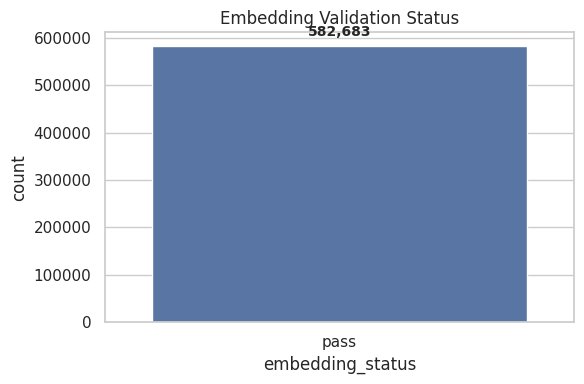

In [5]:
sns.set(style="whitegrid")

# Status bar plot
plt.figure(figsize=(6, 4))
ax = sns.countplot(x="embedding_status", data=df)
plt.title("Embedding Validation Status")
plt.tight_layout()

# Annotate each bar with the count
for p in ax.patches:
    count = int(p.get_height())
    ax.annotate(f'{count:,}',  # comma-separated
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom',
                fontsize=10, fontweight='bold',
                xytext=(0, 5),
                textcoords='offset points')

# Save and show
plt.savefig(EXPORT_DIR / "plot_status_distribution.png")
plt.show()


In [6]:
failed_df = df[df["embedding_status"] == "fail"]
print(f"Number of failed documents: {len(failed_df)}")
columns_of_interest = [
    "_id", "paragraphs", "embeddings",
    "missing_ids", "extra_ids", "bad_ids",
    "mean_cos", "min_cos", "max_delta",
    "determinism_passed"
]

print(failed_df[columns_of_interest].head(10))
output_path = EXPORT_DIR / "embedding_validation_failed_docs.csv"
failed_df[columns_of_interest].to_csv(output_path, index=False)
print(f"🚀 Failed document data saved to: {output_path}")


Number of failed documents: 0
Empty DataFrame
Columns: [_id, paragraphs, embeddings, missing_ids, extra_ids, bad_ids, mean_cos, min_cos, max_delta, determinism_passed]
Index: []
🚀 Failed document data saved to: figures_tables/embeddings_analysis_output/embedding_validation_failed_docs.csv


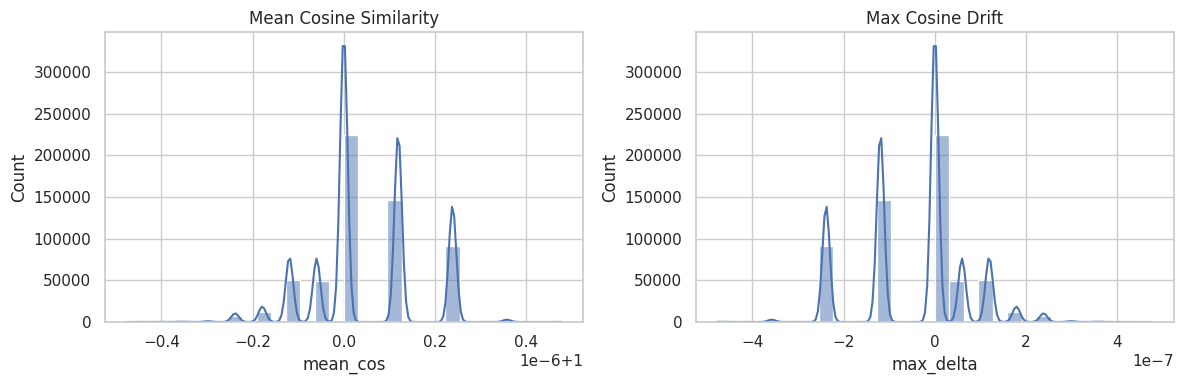

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))  # 1 row, 2 columns

# Mean Cosine Similarity
sns.histplot(df["mean_cos"].dropna(), bins=30, kde=True, ax=axes[0])
axes[0].set_title("Mean Cosine Similarity")

# Max Cosine Drift
sns.histplot(df["max_delta"].dropna(), bins=30, kde=True, ax=axes[1])
axes[1].set_title("Max Cosine Drift")

plt.tight_layout()
plt.savefig(EXPORT_DIR / "subplot_cosine_metrics.png")
plt.show()


In [8]:
# Summary statistics for alignment issue percentages
alignment_summary = df[["missing_pct", "extra_pct", "bad_pct"]].describe().round(4)
alignment_summary


,missing_pct,extra_pct,bad_pct
count,582683.0,582683.0,582683.0
mean,0.0,0.0,0.0
std,0.0,0.0,0.0
min,0.0,0.0,0.0
25%,0.0,0.0,0.0
50%,0.0,0.0,0.0
75%,0.0,0.0,0.0
max,0.0,0.0,0.0


In [9]:
# Summary stats
para_embed_summary = df[["paragraphs", "embeddings"]].describe().round(2)

# Correlation
correlation = df[["paragraphs", "embeddings"]].corr().round(4)

# Mismatches (if any)
mismatch_counts = (df["paragraphs"] != df["embeddings"]).sum()

# Output
print("📋 Paragraph vs Embedding Summary:")
display(para_embed_summary)

print("\n🔗 Pearson Correlation:")
display(correlation)

print(f"\n⚠️ Documents with mismatch: {mismatch_counts}")


📋 Paragraph vs Embedding Summary:


,paragraphs,embeddings
count,582683.00,582683.00
mean,49.47,49.47
std,33.12,33.12
min,3.00,3.00
25%,29.00,29.00
50%,44.00,44.00
75%,62.00,62.00
max,3060.00,3060.00



🔗 Pearson Correlation:


,paragraphs,embeddings
paragraphs,1.0,1.0
embeddings,1.0,1.0



⚠️ Documents with mismatch: 0


In [10]:
alignment_summary.to_csv(EXPORT_DIR / "table_alignment_issue_stats.csv")
para_embed_summary.to_csv(EXPORT_DIR / "table_paragraph_embedding_stats.csv")
correlation.to_csv(EXPORT_DIR / "table_paragraph_embedding_correlation.csv")
